In [1]:
# ==========================================
# PASO 0: IMPORTACIÓN DE LIBRERÍAS ANALÍTICAS
# ==========================================
import numpy as np
import pandas as pd
import random
import re

# Ecosistema de Scikit-Learn para PLN y Clasificación
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Visualización limpia
import matplotlib.pyplot as plt
import seaborn as sns

# Fijar semilla estocástica para reproducibilidad exacta
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("✅ Entorno analítico configurado correctamente.")

✅ Entorno analítico configurado correctamente.


In [2]:
# ==========================================
# PASO 1: CONSTRUCCIÓN DEL GENERADOR LÉXICO
# ==========================================

# Diccionario léxico estructurado por intenciones de comunicación
componentes_texto = {
    "Inofensivo": {
        "sujetos": ["Me encanta", "Excelente trabajo de", "Muy buena la atención de", "Felicidades a", "Interesante la propuesta de", "Me gustaría saber más sobre"],
        "entidades": ["la marca", "el equipo de soporte", "su campaña digital", "la nueva app", "la estrategia de comunicación", "el servicio al cliente"],
        "complementos": ["en su plataforma web.", "continúen así.", "me sirvió mucho la información.", "excelente experiencia de usuario.", "los recomiendo totalmente.", "quedé muy satisfecho."],
        "hashtags": ["#ExcelenteServicio", "#InnovacionDigital", "#Recomendado", "#AnahuacDigital", ""]
    },
    "Queja_Servicio": {
        "sujetos": ["Tengo problemas con", "No funciona correctamente", "Llevo días esperando respuesta de", "Pésima atención en", "Sigue fallando", "Muy lento el proceso de"],
        "entidades": ["la plataforma", "la solicitud de reembolso", "el servicio al cliente", "la aplicación móvil", "el pago en línea", "el sistema de registro"],
        "complementos": ["y nadie me resuelve nada.", "necesito ayuda urgente.", "exijo una solución hoy mismo.", "el sistema marca error.", "no responden los correos.", "es muy frustrante."],
        "hashtags": ["#FallaDeServicio", "#SoporteTecnico", "#AtencionAlCliente", "#SinRespuesta", ""]
    },
    "Crisis_Reputacion": {
        "sujetos": ["Es un verdadero fraude lo de", "Indignante el abuso de", "Exigimos justicia ante", "Totalmente inaceptable la postura de", "Basta de mentiras de", "Escándalo total en"],
        "entidades": ["esta empresa", "la dirección de la marca", "sus directivos", "la campaña engañosa", "el tratamiento de datos", "la institución"],
        "complementos": ["son unos estafadores y corruptos.", "vamos a cancelar nuestras cuentas de inmediato.", "hacemos un llamado masivo al boicot.", "deberían quitarles la licencia.", "difundan esto para que todos sepan la verdad.", "es una vergüenza pública."],
        "hashtags": ["#Boicot", "#FraudeElectoral", "#EscandaloDigital", "#CancelacionDeMarca", "#ExigimosRespuestas", "#Fraude"]
    }
}

def generar_comentario_sintetico(categoria):
    # Genera un texto sintético coherente combinando piezas léxicas según la categoría.
    componente = componentes_texto[categoria]
    suj = random.choice(componente["sujetos"])
    ent = random.choice(componente["entidades"])
    comp = random.choice(componente["complementos"])
    ht = random.choice(componente["hashtags"])
    
    # Construcción final del texto
    texto = f"{suj} {ent} {comp} {ht}".strip()
    return texto

# Prueba del generador léxico
print("--- EJEMPLOS DE TEXTOS SINTÉTICOS GENERADOS ---")
print("Inofensivo:        ", generar_comentario_sintetico("Inofensivo"))
print("Queja de Servicio: ", generar_comentario_sintetico("Queja_Servicio"))
print("Crisis de Reputación:", generar_comentario_sintetico("Crisis_Reputacion"))


--- EJEMPLOS DE TEXTOS SINTÉTICOS GENERADOS ---
Inofensivo:         Me gustaría saber más sobre la marca en su plataforma web. #Recomendado
Queja de Servicio:  No funciona correctamente la solicitud de reembolso necesito ayuda urgente. #FallaDeServicio
Crisis de Reputación: Escándalo total en la institución difundan esto para que todos sepan la verdad. #Boicot


In [3]:
# ==========================================
# PASO 2: CONSTRUCCIÓN DEL DATASET MULTIDIMENSIONAL
# ==========================================

N_MUESTRES = 1500

# Proporciones realistas del mercado (Desbalance de clases)
# 70% Inofensivo, 20% Queja de Servicio, 10% Crisis de Reputación
categorias_prob = ["Inofensivo", "Queja_Servicio", "Crisis_Reputacion"]
pesos_prob = [0.70, 0.20, 0.10]

registros = []

for i in range(N_MUESTRES):
    # Selección estocástica de la categoría real
    cat_real = np.random.choice(categorias_prob, p=pesos_prob)
    
    # Generar texto
    texto = generar_comentario_sintetico(cat_real)
    
    # Generar metadatos asociados según la categoría (inyección de patrones)
    if cat_real == "Crisis_Reputacion":
        plataforma = np.random.choice(["X_Twitter", "TikTok", "Facebook", "Instagram"], p=[0.55, 0.25, 0.10, 0.10])
        retweets = int(np.random.exponential(scale=350) + 50)  # Alto volumen de compartidos
        seguidores = int(np.random.lognormal(mean=9.5, sigma=1.2)) # Usuarios de mayor alcance
        hora = np.random.choice(range(0, 24))
        contiene_hashtag = 1 if "#" in texto else np.random.choice([0, 1], p=[0.2, 0.8])
    elif cat_real == "Queja_Servicio":
        plataforma = np.random.choice(["X_Twitter", "Facebook", "Instagram", "TikTok"], p=[0.40, 0.35, 0.15, 0.10])
        retweets = int(np.random.exponential(scale=25) + 1)
        seguidores = int(np.random.lognormal(mean=6.5, sigma=1.0))
        hora = np.random.choice(range(8, 22))  # Horario laboral
        contiene_hashtag = 1 if "#" in texto else np.random.choice([0, 1], p=[0.6, 0.4])
    else: # Inofensivo
        plataforma = np.random.choice(["Instagram", "Facebook", "TikTok", "X_Twitter"], p=[0.40, 0.30, 0.20, 0.10])
        retweets = int(np.random.exponential(scale=5))
        seguidores = int(np.random.lognormal(mean=5.5, sigma=0.8))
        hora = np.random.choice(range(6, 23))
        contiene_hashtag = 1 if "#" in texto else np.random.choice([0, 1], p=[0.7, 0.3])
    
    # Asignar la variable target numérica (0, 1, 2)
    target = 0 if cat_real == "Inofensivo" else (1 if cat_real == "Queja_Servicio" else 2)
    
    registros.append({
        "id_comentario": f"MSG_{i+1001:04d}",
        "texto_comentario": texto,
        "plataforma": plataforma,
        "retweets_compartidos": retweets,
        "seguidores_usuario": seguidores,
        "hora_publicacion": hora,
        "tiene_hashtag": contiene_hashtag,
        "categoria_etiqueta": cat_real,
        "nivel_riesgo_target": target
    })

# Convertir a DataFrame de Pandas
df_corpus = pd.DataFrame(registros)

# Inyección de nulos sintéticos en ubicacion_usuario (opcional)
df_corpus["ubicacion_usuario"] = np.random.choice(["CDMX", "Monterrey", "Guadalajara", "Puebla", np.nan], size=N_MUESTRES, p=[0.3, 0.15, 0.15, 0.1, 0.3])

print("✅ Dataset Sintético generado exitosamente. Forma:", df_corpus.shape)
print("\n--- DISTRIBUCIÓN DE LAS CLASES DE RIESGO (TARGET) ---")
print(df_corpus["categoria_etiqueta"].value_counts(normalize=True) * 100)


✅ Dataset Sintético generado exitosamente. Forma: (1500, 10)

--- DISTRIBUCIÓN DE LAS CLASES DE RIESGO (TARGET) ---
categoria_etiqueta
Inofensivo           71.600000
Queja_Servicio       18.266667
Crisis_Reputacion    10.133333
Name: proportion, dtype: float64


In [4]:
# Visualizar las primeras filas del dataset
df_corpus.head(10)


,id_comentario,texto_comentario,plataforma,retweets_compartidos,seguidores_usuario,hora_publicacion,tiene_hashtag,categoria_etiqueta,nivel_riesgo_target,ubicacion_usuario
0,MSG_1001,Interesante la propuesta de la nueva app en su...,X_Twitter,6,100,16,1,Inofensivo,0,nan
1,MSG_1002,Me encanta el equipo de soporte continúen así.,Instagram,0,315,8,0,Inofensivo,0,CDMX
2,MSG_1003,Basta de mentiras de esta empresa difundan est...,Facebook,133,7661,11,1,Crisis_Reputacion,2,nan
3,MSG_1004,Me gustaría saber más sobre el servicio al cli...,Instagram,0,168,15,0,Inofensivo,0,Puebla
4,MSG_1005,Totalmente inaceptable la postura de la direcc...,X_Twitter,83,2271,19,1,Crisis_Reputacion,2,CDMX
5,MSG_1006,Muy buena la atención de la marca continúen as...,Instagram,4,803,14,1,Inofensivo,0,nan
6,MSG_1007,Muy buena la atención de su campaña digital co...,X_Twitter,16,151,7,1,Inofensivo,0,Guadalajara
7,MSG_1008,Muy buena la atención de la marca en su plataf...,Facebook,0,522,13,1,Inofensivo,0,Monterrey
8,MSG_1009,Me encanta su campaña digital me sirvió mucho ...,X_Twitter,1,88,11,0,Inofensivo,0,nan
9,MSG_1010,Muy buena la atención de la marca quedé muy sa...,Instagram,9,586,17,1,Inofensivo,0,CDMX


--- MÉTRICAS PROMEDIO POR NIVEL DE RIESGO ---
                    retweets_compartidos  seguidores_usuario  tiene_hashtag
categoria_etiqueta                                                         
Crisis_Reputacion             380.019737        30808.526316       1.000000
Inofensivo                      4.616387          336.257914       0.854749
Queja_Servicio                 26.945255         1074.930657       0.883212


C:\Users\pdani\AppData\Local\Temp\ipykernel_25836\64012938.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_corpus, x="categoria_etiqueta", palette=["#2ca02c", "#ff7f0e", "#d62728"])


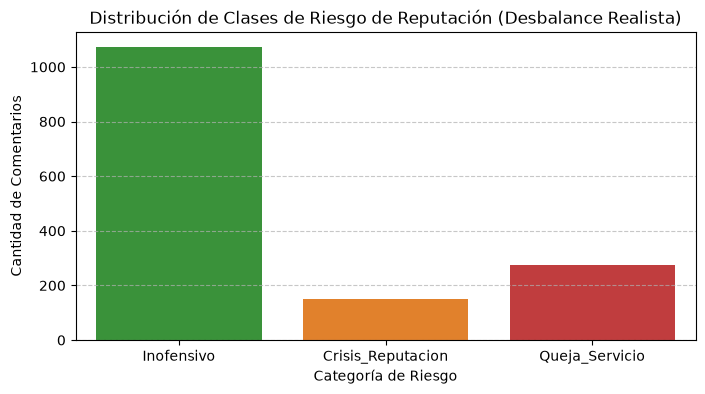

In [5]:
# ==========================================
# PASO 3: ANÁLISIS EXPLORATORIO DE DATOS
# ==========================================
print("--- MÉTRICAS PROMEDIO POR NIVEL DE RIESGO ---")
resumen_stats = df_corpus.groupby("categoria_etiqueta")[["retweets_compartidos", "seguidores_usuario", "tiene_hashtag"]].mean()
print(resumen_stats)

# Graficar la distribución de clases
plt.figure(figsize=(8, 4))
sns.countplot(data=df_corpus, x="categoria_etiqueta", palette=["#2ca02c", "#ff7f0e", "#d62728"])
plt.title("Distribución de Clases de Riesgo de Reputación (Desbalance Realista)")
plt.xlabel("Categoría de Riesgo")
plt.ylabel("Cantidad de Comentarios")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


In [6]:
# ==========================================
# PASO 4: PREPROCESAMIENTO Y TF-IDF
# ==========================================

# Limpieza ligera de texto mediante Expresiones Regulares (Regex)
def limpiar_texto(texto):
    texto = texto.lower() # Convertir a minúsculas
    texto = re.sub(r'[^\w\s#]', '', texto) # Mantener letras, espacios y hashtags
    return texto

df_corpus["texto_limpio"] = df_corpus["texto_comentario"].apply(limpiar_texto)

# Lista de palabras vacías (stopwords) personalizadas en español
stopwords_es = ["de", "la", "que", "el", "en", "y", "a", "los", "del", "se", "las", "por", "un", "para", "con", "no", "una", "su", "al", "lo", "como", "más", "pero", "sus", "le", "ya", "o", "este", "sí", "porque", "esta", "entre", "cuando", "muy", "sin", "sobre", "también", "me", "hasta", "hay", "donde", "quien", "desde", "todo", "nos", "durante", "todos", "uno", "les", "ni", "contra", "otros", "ese", "eso", "ante", "ellos", "e", "esto", "mí", "antes", "algunos", "qué", "unos", "yo", "otro", "otras", "otra", "él", "tanto", "esa", "estos", "mucho", "quienes", "nada", "muchos", "cual", "poco", "ella", "estar", "estas", "algunas", "algo", "nosotros"]

# Instanciar el Vectorizador TF-IDF
tfidf = TfidfVectorizer(max_features=100, stop_words=stopwords_es)

# Ajustar y transformar el cuerpo de texto
X_tfidf = tfidf.fit_transform(df_corpus["texto_limpio"]).toarray()
y = df_corpus["nivel_riesgo_target"].values

print("✅ Matriz TF-IDF generada con éxito. Dimensión de características textuales:", X_tfidf.shape)


✅ Matriz TF-IDF generada con éxito. Dimensión de características textuales: (1500, 100)


--- REPORTE DE CLASIFICACIÓN DEL MODELO PREDICTIVO ---
                      precision    recall  f1-score   support

       0: Inofensivo       0.99      1.00      0.99       215
   1: Queja Servicio       1.00      1.00      1.00        55
2: Crisis Reputación       1.00      0.90      0.95        30

            accuracy                           0.99       300
           macro avg       1.00      0.97      0.98       300
        weighted avg       0.99      0.99      0.99       300



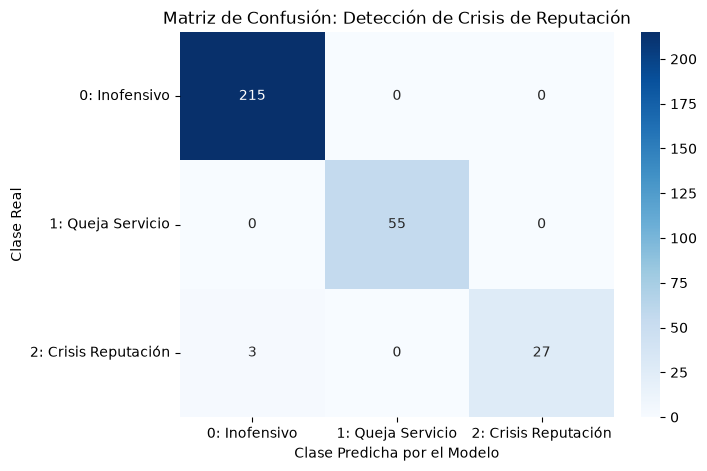

In [7]:
# ==========================================
# PASO 5: ENTRENAMIENTO Y EVALUACIÓN
# ==========================================

# Partición estratificada Train / Test
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y, test_size=0.20, random_state=SEED, stratify=y
)

# Instanciar y entrenar el modelo Random Forest
modelo_crisis = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=SEED, class_weight="balanced")
modelo_crisis.fit(X_train, y_train)

# Predicciones en el conjunto de prueba
y_pred = modelo_crisis.predict(X_test)
y_prob = modelo_crisis.predict_proba(X_test)

# Reporte de Métricas
nombres_clases = ["0: Inofensivo", "1: Queja Servicio", "2: Crisis Reputación"]
print("--- REPORTE DE CLASIFICACIÓN DEL MODELO PREDICTIVO ---")
print(classification_report(y_test, y_pred, target_names=nombres_clases))

# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=nombres_clases, yticklabels=nombres_clases)
plt.title("Matriz de Confusión: Detección de Crisis de Reputación")
plt.xlabel("Clase Predicha por el Modelo")
plt.ylabel("Clase Real")
plt.show()


--- TOP 10 TÉRMINOS MÁS RELEVANTES PARA EL MODELO ---
       Termino  Importancia
        boicot     0.076519
     excelente     0.072021
        fraude     0.064153
       sistema     0.061043
      mentiras     0.043663
soportetecnico     0.043006
        pésima     0.040172
         basta     0.037477
anahuacdigital     0.023525
   inaceptable     0.021565


C:\Users\pdani\AppData\Local\Temp\ipykernel_25836\314421320.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_importancia.head(10), x="Importancia", y="Termino", palette="Oranges_r")


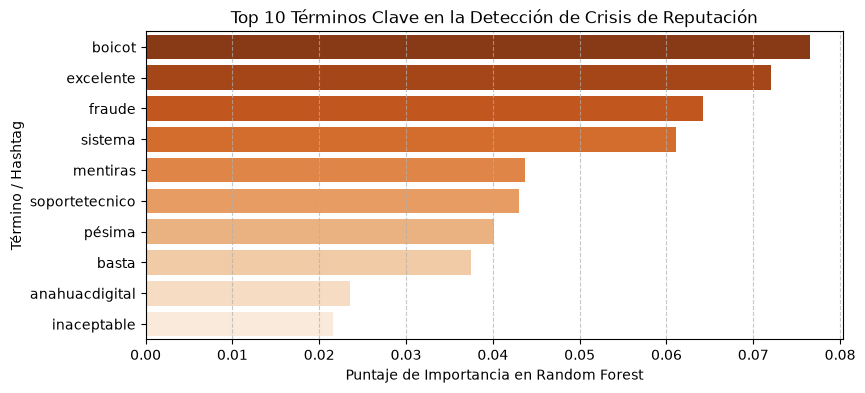

In [8]:
# ==========================================
# PASO 6: IMPORTANCIA DE CARACTERÍSTICAS
# ==========================================

nombres_vocabulario = tfidf.get_feature_names_out()
importancias = modelo_crisis.feature_importances_

df_importancia = pd.DataFrame({
    "Termino": nombres_vocabulario,
    "Importancia": importancias
}).sort_values(by="Importancia", ascending=False)

print("--- TOP 10 TÉRMINOS MÁS RELEVANTES PARA EL MODELO ---")
print(df_importancia.head(10).to_string(index=False))

# Graficar los términos principales
plt.figure(figsize=(9, 4))
sns.barplot(data=df_importancia.head(10), x="Importancia", y="Termino", palette="Oranges_r")
plt.title("Top 10 Términos Clave en la Detección de Crisis de Reputación")
plt.xlabel("Puntaje de Importancia en Random Forest")
plt.ylabel("Término / Hashtag")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()
